# Brightband VPR correction (Zhang & Qi 2010) on KTLX, 5 May 2022

**Question.** Notebook 01 found that our hourly totals overestimate MRMS gauge-corrected rain by 17-53 % at
100-150 km from KTLX, where the 0.5 deg beam starts to sample the melting layer. Does the NMQ/MRMS brightband
correction of Zhang & Qi (2010, J. Hydrometeor., doi:10.1175/2010JHM1201.1) remove that?

**Method** (`radarwow.estimation.ZhangQi2010VPR`): stratiform columns (VIL <= 6.5 kg m-2) with composite
Z >= 30 dBZ, between the apparent BB top (HRRR 0 C height + half the lowest beam's depth there) and 5 km below
it, form the brightband-affected area. Each tilt's apparent VPR (azimuthal mean Z per range) is fitted with a
five-parameter linear model, and the modelled excess above the flat rain profile is subtracted.

Same chain, same case and same reference (MRMS MultiSensor QPE Pass 2) as notebook 01; the only change is the
reflectivity fed to the rain relations.

In [1]:
# Colab: uncomment to install (downloads ~700 MB of radar data on first run)
!pip install -q cfgrib eccodes "git+https://github.com/manmeet3591/radarwow-core" "git+https://github.com/manmeet3591/radarwow-kdp" "git+https://github.com/manmeet3591/radarwow-attenuation" "git+https://github.com/manmeet3591/radarwow-estimation" "git+https://github.com/manmeet3591/radarwow-classification" "git+https://github.com/manmeet3591/radarwow-verify"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from radarwow.attenuation import Testud2000ZPHI
from radarwow.classification import MeltingLayerTracker, melting_layer_from_volume
from radarwow.core import nexrad_aws_files, open_volume
from radarwow.estimation import SyntheticRainRate, ZhangQi2010VPR, ZRRelation, accumulate, to_fixed_azimuths
from radarwow.estimation.vpr import beam_height_km
from radarwow.kdp import Vulpiani2012KDP
from radarwow.verify import fetch_mrms, gate_latlon, hrrr_freezing_level, scores, to_mrms_grid

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
SITE, START, END = "KTLX", "2022-05-05 06:00", "2022-05-05 11:00"
HOURS = [7, 8, 9, 10]
NG = 600  # gates to 150 km

## 1. Run the chain on every volume, with and without VPR correction

In [3]:
files = nexrad_aws_files(SITE, START, END, cache_dir=f"{CACHE}/nexrad")
tracker = MeltingLayerTracker()
fz_cache, fits, profiles = {}, [], {}
METHODS = ["synthetic", "synthetic + VPR", "Z-R Marshall-Palmer", "Z-R Marshall-Palmer + VPR"]
scans = {k: [] for k in METHODS}
corr_sum, corr_n = None, 0
for t, f in files:
    dt = open_volume(f, band="S")
    lat0, lon0, alt = float(dt["latitude"].values), float(dt["longitude"].values), float(dt["altitude"].values)
    hr = pd.Timestamp(t).round("h")
    if hr not in fz_cache:
        fz_cache[hr] = (hrrr_freezing_level(hr, lat0, lon0, f"{CACHE}/hrrr", 150) - alt) / 1e3
    fz = fz_cache[hr]
    ml, _ = melting_layer_from_volume(dt)
    use, _ = tracker.update(t, ml)
    mlb = use.bottom_km if use else None
    vpr = ZhangQi2010VPR(freezing_level_km=fz)
    vdt = vpr(dt)
    low = vpr.fits[0]
    fits.append(dict(time=pd.Timestamp(t), fz=fz, h_top=vpr.h_top, ml_bottom=mlb, ml_top=use.top_km if use else np.nan,
                     corrected=low.corrected, symmetric=low.symmetric, h_peak=low.h_peak, h_bottom=low.h_bottom,
                     alpha=low.alpha, beta=low.beta, reason=low.reason,
                     n_tilts_corrected=sum(x.corrected for x in vpr.fits), n_tilts=len(vpr.fits)))
    profiles[pd.Timestamp(t)] = low
    ds = vdt[low.sweep].to_dataset().isel(range=slice(0, NG))
    if "PHIDP" not in ds:
        raise RuntimeError(f"{low.sweep} has no PHIDP")
    att = Testud2000ZPHI()(Vulpiani2012KDP()(ds, band="S"), band="S")
    att_v = att.assign(DBZH=att["DBZH_VPR"])
    ds_v = ds.assign(DBZH=ds["DBZH_VPR"])
    rates = {"synthetic": SyntheticRainRate(temperature_c=20, ml_bottom_km=mlb)(att, band="S")["RATE"],
             "synthetic + VPR": SyntheticRainRate(temperature_c=20, ml_bottom_km=mlb)(att_v, band="S")["RATE"],
             "Z-R Marshall-Palmer": ZRRelation(preset="marshall_palmer", z_max_dbz=53, ml_bottom_km=mlb)(ds, band="S")["RATE_Z"],
             "Z-R Marshall-Palmer + VPR": ZRRelation(preset="marshall_palmer", z_max_dbz=53, ml_bottom_km=mlb)(ds_v, band="S")["RATE_Z"]}
    for k, v in rates.items():
        scans[k].append((t, to_fixed_azimuths(v)))
    c = to_fixed_azimuths(ds["VPR_CORRECTION"]).values
    corr_sum = c if corr_sum is None else corr_sum + c
    corr_n += 1
    meta = dict(range=ds["range"].values, elevation=float(np.nanmedian(ds["elevation"].values)), lat=lat0, lon=lon0)
fits = pd.DataFrame(fits)
display(Markdown(f"{len(fits)} volumes; lowest tilt corrected in {fits.corrected.sum()}, "
                 f"symmetric model in {fits.symmetric.sum()}. Reasons for no correction: "
                 + "; ".join(f"{r} ({n})" for r, n in fits[~fits.corrected].reason.value_counts().items())))

44 volumes; lowest tilt corrected in 33, symmetric model in 0. Reasons for no correction: slope above the peak is 0.47 dB/km (must be < 0) (1); slope above the peak is 0.39 dB/km (must be < 0) (1); slope above the peak is 0.71 dB/km (must be < 0) (1); slope above the peak is 2.46 dB/km (must be < 0) (1); slope above the peak is 1.08 dB/km (must be < 0) (1); slope above the peak is 1.44 dB/km (must be < 0) (1); slope above the peak is 0.81 dB/km (must be < 0) (1); slope above the peak is 0.06 dB/km (must be < 0) (1); slope above the peak is 0.56 dB/km (must be < 0) (1); slope above the peak is 0.08 dB/km (must be < 0) (1); no BB bottom found and the maximum is 1.6 km below the BB top (not a bright band near the ground) (1)

## 2. What the lowest tilt's apparent VPR looks like

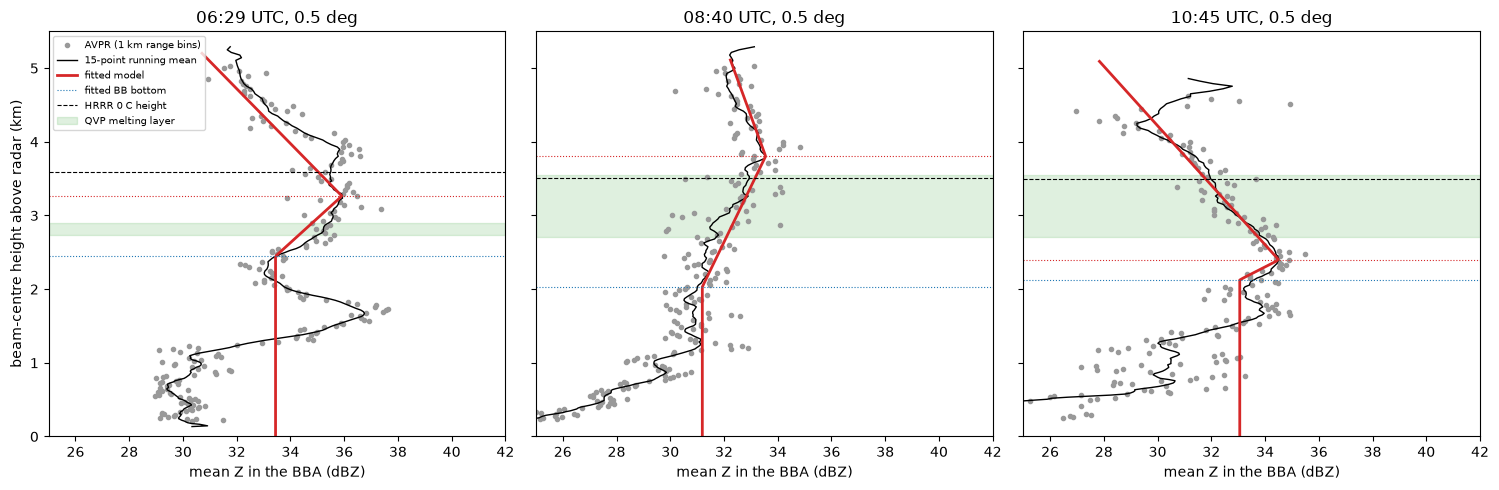

In [4]:
times = [fits.time.iloc[i] for i in (3, len(fits) // 2, len(fits) - 3)]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, t in zip(axes, times):
    p = profiles[t]
    ax.plot(p.profile_z, p.profile_h, ".", color="0.6", label="AVPR (1 km range bins)")
    if p.profile_smooth.size:
        ax.plot(p.profile_smooth, p.profile_h, "k-", lw=1, label="15-point running mean")
    if p.corrected:
        hh = np.linspace(0, p.h_top, 200)
        zb = p.z_peak - p.beta * (p.h_peak - p.h_bottom)
        ax.plot(zb + p.delta_db(hh), hh, "C3", lw=2, label="fitted model")
        ax.axhline(p.h_peak, color="C3", ls=":", lw=0.8)
        ax.axhline(p.h_bottom, color="C0", ls=":", lw=0.8, label="fitted BB bottom")
    row = fits[fits.time == t].iloc[0]
    ax.axhline(row.fz, color="k", ls="--", lw=0.8, label="HRRR 0 C height")
    if np.isfinite(row.ml_top):
        ax.axhspan(row.ml_bottom, row.ml_top, color="C2", alpha=0.15, label="QVP melting layer")
    ax.set(title=f"{t:%H:%M} UTC, {p.elevation:.1f} deg" + ("" if p.corrected else "\nnot corrected: " + p.reason[:40]),
           xlabel="mean Z in the BBA (dBZ)", xlim=(25, 42), ylim=(0, 5.5))
axes[0].set_ylabel("beam-centre height above radar (km)")
axes[0].legend(fontsize=7, loc="upper left")
fig.tight_layout()
fig.savefig(f"{FIG}/04_vpr_profiles.png", dpi=110)
plt.show()

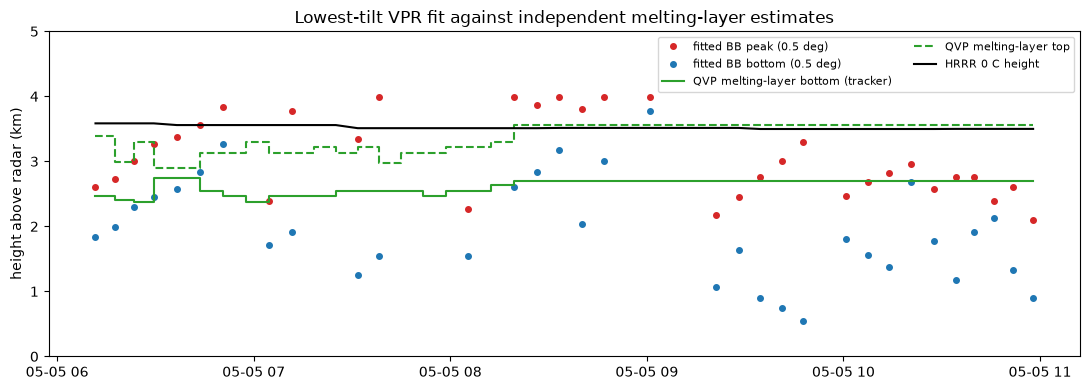

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
c = fits[fits.corrected]
ax.plot(c.time, c.h_peak, "C3o", ms=4, label="fitted BB peak (0.5 deg)")
ax.plot(c.time, c.h_bottom, "C0o", ms=4, label="fitted BB bottom (0.5 deg)")
ax.step(fits.time, fits.ml_bottom, where="post", color="C2", label="QVP melting-layer bottom (tracker)")
ax.step(fits.time, fits.ml_top, where="post", color="C2", ls="--", label="QVP melting-layer top")
ax.plot(fits.time, fits.fz, "k-", label="HRRR 0 C height")
ax.set(ylabel="height above radar (km)", ylim=(0, 5), title="Lowest-tilt VPR fit against independent melting-layer estimates")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(f"{FIG}/05_vpr_fit_timeseries.png", dpi=110)
plt.show()

## 3. Hourly totals against MRMS, by distance from the radar

In [6]:
az = (np.arange(720) + 0.5) * 0.5
lat, lon, ground = gate_latlon(meta["range"], az, meta["elevation"], meta["lat"], meta["lon"])
gk = ground / 1e3
results, maps = [], {}
RINGS = [(0, 150), (0, 50), (50, 100), (100, 150)]
for h in HOURS:
    a, b = pd.Timestamp(f"2022-05-05 {h:02d}:00"), pd.Timestamp(f"2022-05-05 {h + 1:02d}:00")
    ref = fetch_mrms("gauge_corrected", b, f"{CACHE}/mrms")
    for k, sc in scans.items():
        acc = accumulate(sc, a, b)
        val = np.where(acc["VALID_MINUTES"].values >= 48, acc["ACCUM"].values, np.nan)
        maps[(h, k)] = val
        ours, theirs, dist = to_mrms_grid(val, lat, lon, ref, gk)
        for lo_, hi_ in RINGS:
            m = (dist >= lo_) & (dist < hi_)
            results.append(dict(hour=f"{h:02d}-{h + 1:02d}", method=k, ring=f"{lo_}-{hi_} km", **scores(ours[m], theirs[m])))
res = pd.DataFrame(results)
for ring in ["0-150 km", "100-150 km"]:
    tab = res[res.ring == ring].pivot_table(index="method", columns="hour", values=["bias_ratio", "corr"]).round(2)
    display(Markdown(f"**{ring}** (bias = our total / MRMS gauge-corrected total)\n\n" + tab.loc[METHODS].to_markdown()))

**0-150 km** (bias = our total / MRMS gauge-corrected total)

| method                    |   ('bias_ratio', '07-08') |   ('bias_ratio', '08-09') |   ('bias_ratio', '09-10') |   ('bias_ratio', '10-11') |   ('corr', '07-08') |   ('corr', '08-09') |   ('corr', '09-10') |   ('corr', '10-11') |
|:--------------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| synthetic                 |                      1.18 |                      1.06 |                      1.18 |                      1.08 |                0.94 |                0.93 |                0.92 |                0.77 |
| synthetic + VPR           |                      1.14 |                      1.05 |                      1.11 |                      1.02 |                0.94 |                0.93 |                0.93 |                0.78 |
| Z-R Marshall-Palmer       |                      1.11 |                      0.98 |                      1.11 |                      1.03 |                0.93 |                0.89 |                0.9  |                0.84 |
| Z-R Marshall-Palmer + VPR |                      1.08 |                      0.97 |                      1.05 |                      0.98 |                0.93 |                0.9  |                0.92 |                0.86 |

**100-150 km** (bias = our total / MRMS gauge-corrected total)

| method                    |   ('bias_ratio', '07-08') |   ('bias_ratio', '08-09') |   ('bias_ratio', '09-10') |   ('bias_ratio', '10-11') |   ('corr', '07-08') |   ('corr', '08-09') |   ('corr', '09-10') |   ('corr', '10-11') |
|:--------------------------|--------------------------:|--------------------------:|--------------------------:|--------------------------:|--------------------:|--------------------:|--------------------:|--------------------:|
| synthetic                 |                      1.22 |                      1.17 |                      1.53 |                      1.22 |                0.93 |                0.86 |                0.81 |                0.63 |
| synthetic + VPR           |                      1.17 |                      1.15 |                      1.32 |                      1.06 |                0.93 |                0.84 |                0.83 |                0.69 |
| Z-R Marshall-Palmer       |                      1.11 |                      1.15 |                      1.51 |                      1.2  |                0.92 |                0.86 |                0.83 |                0.65 |
| Z-R Marshall-Palmer + VPR |                      1.07 |                      1.12 |                      1.32 |                      1.05 |                0.92 |                0.87 |                0.84 |                0.7  |

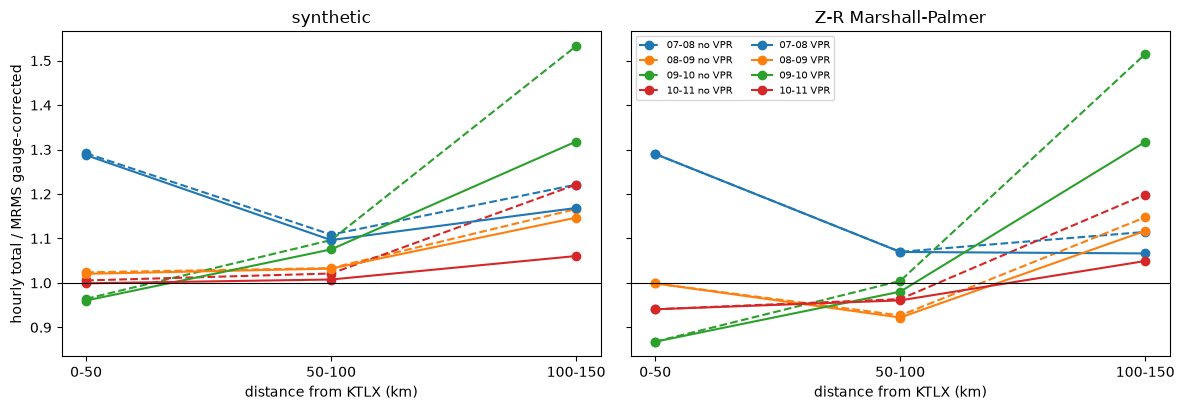

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, base in zip(axes, ["synthetic", "Z-R Marshall-Palmer"]):
    for k, ls in [(base, "--"), (base + " + VPR", "-")]:
        r = res[(res.method == k) & (res.ring != "0-150 km")]
        for i, (hour, g) in enumerate(r.groupby("hour")):
            ax.plot(range(3), g.set_index("ring").loc[["0-50 km", "50-100 km", "100-150 km"], "bias_ratio"], ls,
                    color=f"C{i}", marker="o", label=f"{hour} {'VPR' if 'VPR' in k else 'no VPR'}")
    ax.axhline(1, color="k", lw=0.8)
    ax.set(xticks=range(3), xticklabels=["0-50", "50-100", "100-150"], xlabel="distance from KTLX (km)", title=base)
axes[0].set_ylabel("hourly total / MRMS gauge-corrected")
axes[1].legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(f"{FIG}/06_vpr_bias_by_range.png", dpi=110)
plt.show()

## 4. Where the correction acts

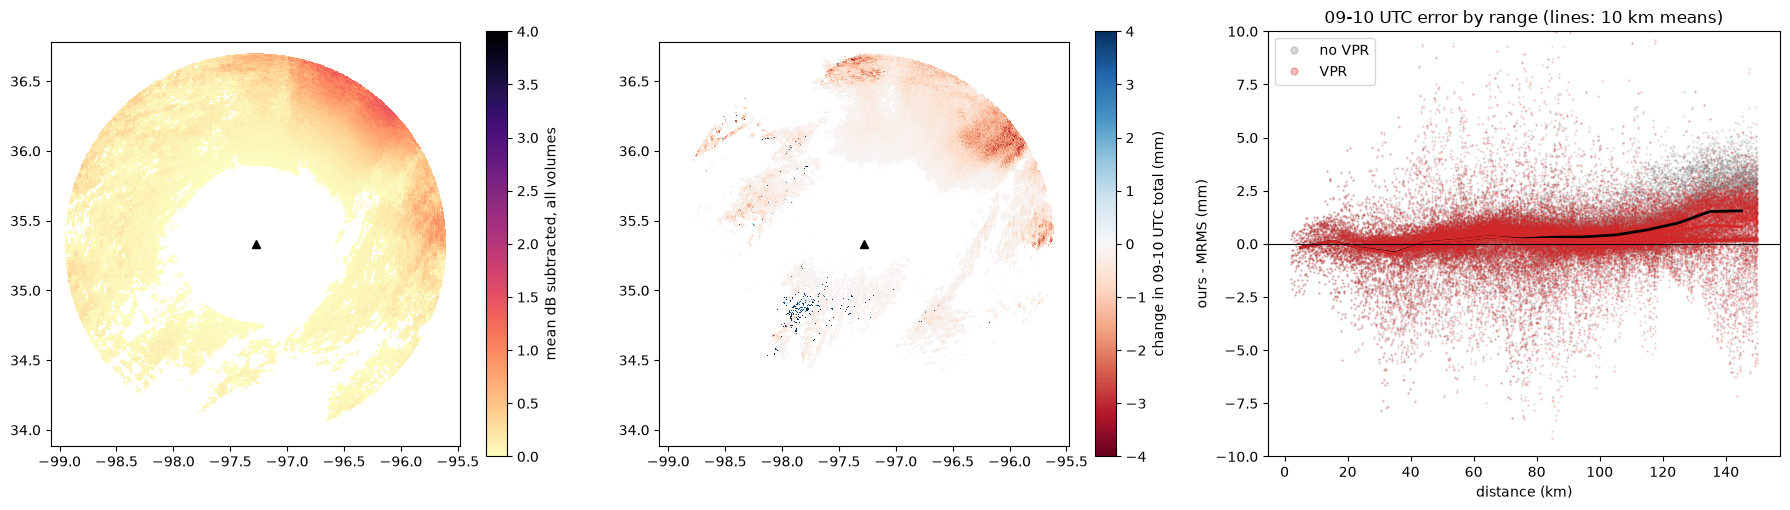

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
mean_corr = corr_sum / corr_n
kw = dict(shading="auto")
m0 = axes[0].pcolormesh(lon, lat, np.ma.masked_less_equal(mean_corr, 0.01), cmap="magma_r", vmin=0, vmax=4, **kw)
fig.colorbar(m0, ax=axes[0], label="mean dB subtracted, all volumes")
h = 9
d = maps[(h, "synthetic + VPR")] - maps[(h, "synthetic")]
m1 = axes[1].pcolormesh(lon, lat, np.ma.masked_inside(d, -0.05, 0.05), cmap="RdBu", vmin=-4, vmax=4, **kw)
fig.colorbar(m1, ax=axes[1], label=f"change in {h:02d}-{h + 1:02d} UTC total (mm)")
ref = fetch_mrms("gauge_corrected", pd.Timestamp(f"2022-05-05 {h + 1:02d}:00"), f"{CACHE}/mrms")
both = np.isfinite(maps[(h, "synthetic + VPR")]) & np.isfinite(maps[(h, "synthetic")])
o, t_, dist = to_mrms_grid(np.where(both, maps[(h, "synthetic + VPR")], np.nan), lat, lon, ref, gk)
o0, _, _ = to_mrms_grid(np.where(both, maps[(h, "synthetic")], np.nan), lat, lon, ref, gk)
ok = np.isfinite(t_) & ((t_ > 0.1) | (o > 0.1))
axes[2].plot(dist[ok], (o0 - t_)[ok], ".", ms=1, alpha=0.3, color="0.5", label="no VPR")
axes[2].plot(dist[ok], (o - t_)[ok], ".", ms=1, alpha=0.3, color="C3", label="VPR")
bins = np.arange(0, 151, 10)
for v, col in [(o0, "k"), (o, "C3")]:
    e = v - t_
    med = [np.nanmean(e[ok & (dist >= lo_) & (dist < lo_ + 10)]) for lo_ in bins[:-1]]
    axes[2].plot(bins[:-1] + 5, med, "-", color=col, lw=2)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set(xlabel="distance (km)", ylabel="ours - MRMS (mm)", ylim=(-10, 10), title=f"{h:02d}-{h + 1:02d} UTC error by range (lines: 10 km means)")
axes[2].legend(markerscale=10)
for a_ in axes[:2]:
    a_.set(xlim=(meta["lon"] - 1.8, meta["lon"] + 1.8), ylim=(meta["lat"] - 1.45, meta["lat"] + 1.45), aspect=1 / np.cos(np.deg2rad(meta["lat"])))
    a_.plot(meta["lon"], meta["lat"], "k^")
fig.tight_layout()
fig.savefig(f"{FIG}/07_vpr_maps.png", dpi=95)
plt.show()

## Takeaways
- **The far-range overestimate shrinks in every hour.** At 100-150 km the synthetic estimate's bias falls from
  1.22 / 1.17 / 1.53 / 1.22 to 1.17 / 1.15 / 1.32 / 1.06 (07-11 UTC), with correlation unchanged or better
  (0.63 -> 0.69 in the last hour). Z-R Marshall-Palmer behaves the same way. Within 100 km nothing changes,
  as it should: the beam is below the bright band there.
- **Over the whole 150 km disk** the synthetic bias goes from 1.06-1.18 to 1.02-1.14.
- **Half of the far-range excess is left** in the worst hour (09-10 UTC, 1.32). The correction is only applied in
  stratiform columns with composite Z >= 30 dBZ (the paper's brightband-affected area), so lighter rain seen
  through the bright band is not corrected; and the per-tilt fit is noisy (below).
- **The fits are noisy on this case.** The bright band is weak (2-4 dB) and patchy, and the lowest tilt's apparent
  VPR mixes height with horizontal rain structure (e.g. the 37 dBZ bump at 1.7 km at 06:29 is most likely a rain feature, not melting).
  Fitted peaks range 2.1-4.0 km and some sit at the edge of the search window around the 0 C level (radar-wow's
  addition; without it the peak wandered up to 4.3 km); some fitted bottoms are as low as 0.6-1 km, well below
  the QVP melting-layer bottom (2.5-2.7 km). 11 of 44 volumes were not corrected (10: no negative slope above the peak; 1: no bottom found).
- **Not tuned on this case.** Tighter priors (the QVP melting layer for the peak and bottom, or fitting all tilts
  jointly) are the obvious next step, but must be chosen on other events to avoid fitting the verification case.
- **Open:** one radar, one stratiform-with-weak-BB case; ice-region correction above the bright band (Qi et al.
  2013) and the dual-pol VPR of Hanft et al. 2023 not implemented.